# 03 · Preprocessing and features

How does a lesion become a model input? This notebook covers the image transforms at evaluation and training time,
how a missing clinical image is handled, how malformed rows are made safe, and which metadata fields the model uses.

_This model was developed for a research competition and is not a medical device._

In [1]:
# Setup: every path comes from configs/final.yaml (milk10k.config); nothing here downloads data.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RELEASE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(RELEASE / "src") not in sys.path:
    sys.path.insert(0, str(RELEASE / "src"))  # works without `pip install -e .`
from milk10k.config import load_config
from milk10k.dataset import MILKDataset, clinical_transforms, derm_transforms, encode_tabular

cfg = load_config()
DATA = cfg["paths"]["data_dir"]  # prepared MILK10k (data/README.md); override with MILK10K_DATA_DIR

# "data:<file>" = under DATA; anything else is relative to the release root.
INPUTS = {
    "train_meta": "data:train_metadata.csv",
    "folds": "data/folds.csv",
    "image_sizes": "results/tables/01_image_sizes.csv",
    "tabular_encoding": "models/final-P1a-kg/tabular_encoding.json"
}
OUTPUTS = {
    "table_feature_roles": "results/tables/03_feature_roles.csv",
    "table_feature_description": "results/tables/03_feature_description.csv"
}


def inp(key):
    v = INPUTS[key]
    return DATA / v[5:] if v.startswith("data:") else RELEASE / v


def out(key):
    p = RELEASE / OUTPUTS[key]
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def savefig(key):
    plt.tight_layout()
    plt.savefig(out(key), dpi=120)
    plt.show()


missing = [k for k in INPUTS if not inp(k).exists()]
import os  # noqa: E402
print("data dir from:", "MILK10K_DATA_DIR" if os.environ.get("MILK10K_DATA_DIR") else "configs/final.yaml")
print("checkpoints from:", "MILK10K_CHECKPOINT_DIR" if os.environ.get("MILK10K_CHECKPOINT_DIR") else "configs/final.yaml")
print("missing inputs:", missing or "none")

<release>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


data dir from: MILK10K_DATA_DIR
checkpoints from: configs/final.yaml
missing inputs: none


## 1. Evaluation preprocessing
At evaluation time dermoscopy is resized to a 288×288 square: no crop, so the whole frame is kept but stretched.
Clinical photos are letterboxed: the longest side becomes 288 and the rest is zero-padded. How large are the
distortion and the padding on these images?

In [2]:
S = cfg["recipe"]["img_size"]
print("derm (eval):", derm_transforms(S, train=False))
print("clinical (eval):", clinical_transforms(S, train=False))
sizes = pd.read_csv(inp("image_sizes"))
derm, clin = sizes[sizes.modality == "derm"], sizes[sizes.modality == "clinical"]
aniso = derm.width / derm.height
pad = 1 - np.minimum(clin.width, clin.height) / np.maximum(clin.width, clin.height)
print(f"derm square-resize anisotropy (width/height): median {aniso.median():.3f}, range {aniso.min():.3f}-{aniso.max():.3f}")
print(f"clinical letterbox padding share of the canvas: median {pad.median():.3f}")

derm (eval): Compose([
  Resize(p=1.0, area_for_downscale=None, height=288, interpolation=1, mask_interpolation=0, width=288),
  Normalize(p=1.0, max_pixel_value=255.0, mean=(0.485, 0.456, 0.406), normalization='standard', std=(0.229, 0.224, 0.225)),
  ToTensorV2(p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)
clinical (eval): Compose([
  LongestMaxSize(p=1.0, area_for_downscale=None, interpolation=1, mask_interpolation=0, max_size=288, max_size_hw=None),
  PadIfNeeded(p=1.0, border_mode=0, fill=0.0, fill_mask=0.0, min_height=288, min_width=288, pad_height_divisor=None, pad_width_divisor=None, padding=0, position='center'),
  Normalize(p=1.0, max_pixel_value=255.0, mean=(0.485, 0.456, 0.406), normalization='standard', std=(0.229, 0.224, 0.225)),
  ToTensorV2(p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)
derm square-resize anisotropy

Every image is 600×450, so every dermoscopic image is stretched by exactly 1.333×. The letterbox pads exactly a quarter
of the clinical canvas. Both are the same for every lesion.

## 2. Training augmentation
Each stream has its own Albumentations pipeline. Note the `GaussNoise` child inside a `OneOf` in both streams: section 3
shows what it does to an image.

In [3]:
print("derm (train):", derm_transforms(S, train=True))
print()
print("clinical (train):", clinical_transforms(S, train=True))

derm (train): Compose([
  RandomResizedCrop(p=1.0, area_for_downscale=None, interpolation=1, mask_interpolation=0, ratio=(0.8, 1.25), scale=(0.5, 1.0), size=(288, 288)),
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.5),
  RandomRotate90(p=1.0),
  Affine(p=0.5, balanced_scale=False, border_mode=0, fill=0.0, fill_mask=0.0, fit_output=False, interpolation=1, keep_ratio=False, mask_interpolation=0, rotate=(-45.0, 45.0), rotate_method='largest_box', scale={'x': (0.9, 1.1), 'y': (0.9, 1.1)}, shear={'x': (0.0, 0.0), 'y': (0.0, 0.0)}, translate_percent=None, translate_px={'x': (0, 0), 'y': (0, 0)}),
  HairAugmentation(p=0.3, num_hairs=(5, 30)),
  ColorJitter(p=0.7, brightness=(0.8, 1.2), contrast=(0.8, 1.2), hue=(-0.02, 0.02), saturation=(0.85, 1.15)),
  OneOf([
    GaussianBlur(p=0.5, blur_limit=(3, 5), sigma_limit=(0.5, 3.0)),
    MotionBlur(p=0.5, allow_shifted=True, angle_range=(0.0, 360.0), blur_limit=(3, 5), direction_range=(-1.0, 1.0)),
    GaussNoise(p=0.5, mean_range=(0.0, 0.0), noise_s

## 3. What the model actually sees
The evaluation and training views of one training lesion, after normalisation. Seeds are fixed so the views are the
same on every run. Images are shown as a small embedded JPEG and not saved.

eval {'derm': (3, 288, 288), 'clin': (3, 288, 288)} | derm channel mean [ 0.271 -0.061 -0.083] std [0.395 0.447 0.439]
train {'derm': (3, 288, 288), 'clin': (3, 288, 288)} | derm channel mean [ 0.219 -0.075 -0.114] std [0.434 0.495 0.477]


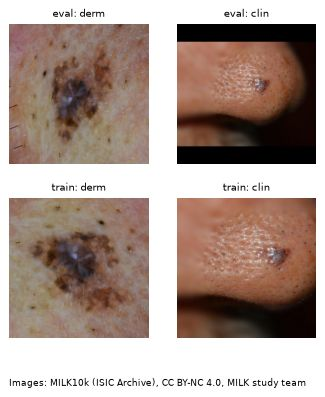

In [4]:
import io
import random

from IPython.display import Image, display

from milk10k.dataset import IMNET_MEAN, IMNET_STD

SHOW_IMAGES = True  # small embedded JPEG; never saved to results/


def show_jpeg(fig):
    """Display a figure as a small embedded JPEG with the image credit, then close it."""
    fig.text(0.5, 0.0, "Images: MILK10k (ISIC Archive), CC BY-NC 4.0, MILK study team", ha="center", fontsize=7)
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=90, bbox_inches="tight", pil_kwargs={"quality": 80})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format="jpeg"))


def to_rgb(t):
    return np.clip(t.permute(1, 2, 0).numpy() * np.array(IMNET_STD) + np.array(IMNET_MEAN), 0, 1)


train = pd.read_csv(inp("train_meta")).merge(pd.read_csv(inp("folds"))[["isic_id", "fold"]], on="isic_id")
demo = train.head(2)
views = {}
for name, is_train in (("eval", False), ("train", True)):
    ds = MILKDataset(demo, str(DATA), derm_transforms(S, train=is_train), clinical_transforms(S, train=is_train),
                     clin_size=S, train=is_train)
    random.seed(0)  # clinical dropout draw
    ds.derm_tf.set_random_seed(0)
    ds.clin_tf.set_random_seed(0)
    item = views[name] = ds[0]
    print(name, {k: tuple(v.shape) for k, v in item.items() if hasattr(v, "shape") and v.ndim},
          "| derm channel mean", item["derm"].mean((1, 2)).numpy().round(3), "std", item["derm"].std((1, 2)).numpy().round(3))
if SHOW_IMAGES:
    fig, axes = plt.subplots(2, 2, figsize=(4.4, 4.6))
    for row, name in enumerate(("eval", "train")):
        for col, key in enumerate(("derm", "clin")):
            axes[row, col].imshow(to_rgb(views[name][key]))
            axes[row, col].set_title(f"{name}: {key}", fontsize=8)
            axes[row, col].axis("off")
    show_jpeg(fig)

### What GaussNoise does to an image
In training, `GaussNoise` (default settings) is one of three options inside a `OneOf`, with two blur transforms.
To see its effect in isolation we apply the same transform, forced on and with a fixed seed, to the resized
dermoscopy of the same lesion. This only illustrates the transform; the training pipeline is unchanged.

RMS difference after ImageNet normalisation: 1.419


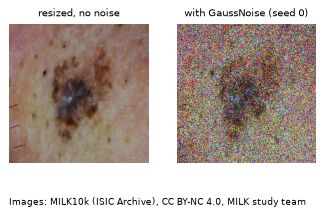

In [5]:
import albumentations as A

from milk10k.dataset import read_rgb

clean = A.Resize(S, S)(image=read_rgb(str(DATA / demo.iloc[0].derm_image_path)))["image"]
noisy = A.Compose([A.GaussNoise(p=1.0)], seed=0)(image=clean)["image"]  # pipeline defaults, forced on, fixed seed
normalise = A.Normalize(IMNET_MEAN, IMNET_STD)
rms = float(np.sqrt(np.mean((normalise(image=noisy)["image"] - normalise(image=clean)["image"]) ** 2)))
print(f"RMS difference after ImageNet normalisation: {rms:.3f}")
if SHOW_IMAGES:
    fig, axes = plt.subplots(1, 2, figsize=(4.4, 2.5))
    for a, img, title in zip(axes, (clean, noisy), ("resized, no noise", "with GaussNoise (seed 0)")):
        a.imshow(img)
        a.set_title(title, fontsize=8)
        a.axis("off")
    show_jpeg(fig)

The noise is strong. On this image it changes the normalised tensor by 1.42 RMS units. In the training views we checked
during the GaussNoise investigation the effect was 0.63–0.98, so the exact amount varies from image to image. Damage
this visible made GaussNoise our first suspect. Turning it off did not help, however: pAUC80 and macro-AUC both fell
(notebook 06, `docs/experiment_log.md`).

## 4. A missing clinical image
Real referrals often come without a clinical photo. What does the model receive then? A blank path gives a zero
tensor and `clin_mask = False`, and the model replaces the clinical token with a learned `[NULL]` token. During
training the clinical image is dropped at random to teach this case.

In [6]:
import inspect

from milk10k.models import MILKFusionNet

blank = demo.copy()
blank["clinical_image_path"] = ""
item = MILKDataset(blank, str(DATA), derm_transforms(S, False), clinical_transforms(S, False), clin_size=S)[0]
print("clin_mask:", bool(item["clin_mask"]), "| clinical tensor all zeros:", bool((item["clin"] == 0).all()))
print("training-time clinical dropout:", inspect.signature(MILKDataset.__init__).parameters["p_drop_clin"].default)
print(inspect.getsource(MILKFusionNet.forward))

clin_mask: False | clinical tensor all zeros: True
training-time clinical dropout: 0.15
    def forward(self, derm, clin, clin_mask, site, sex, fst, age, age_missing):
        b = derm.shape[0]
        if len(self.xattn):
            td = self.derm_proj(feature_tokens(self.derm, derm))
            tc = self.clin_proj(feature_tokens(self.clin, clin))
            for blk in self.xattn:
                td, tc = blk(td, tc, clin_mask)
            z_d, z_c = td.mean(1), tc.mean(1)
        else:
            z_d = self.derm_proj(self.derm(derm))
            z_c = self.clin_proj(self.clin(clin))
        z_c = torch.where(clin_mask[:, None], z_c, self.null_clin.expand(b, -1))
        z_t = self.tab(site, sex, fst, age, age_missing)

        tokens = torch.cat([self.cls_token.expand(b, -1, -1),
                            torch.stack([z_d, z_c, z_t], dim=1)], dim=1) + self.type_emb
        h = self.norm(self.fusion(tokens)[:, 0])
        return self.head_cls(h), self.head_bin(h).squeeze(1)



The blank path behaves as intended. The clinical image is dropped for 15% of training samples, so the `[NULL]` path is
trained, not just tolerated.

## 5. Making malformed rows safe
Inference should never crash on a bad row. `milk10k.inference.sanitize_inputs` handles these cases:
- a blank, NaN, missing-file or unreadable clinical image becomes a missing clinical image;
- an unreadable dermoscopic image marks the row, which later receives the training prior instead of a prediction;
- a skin-tone code outside 1–6, or an unseen site or sex, becomes missing;
- a duplicate ID keeps only its first row.

We feed it seven training rows with injected faults plus one duplicate.

In [7]:
from milk10k.inference import sanitize_inputs

faulty = train.drop(columns=["diagnostic_class_11", "target_binary", "diagnosis_confirm_type", "fold"],
                    errors="ignore").head(7).copy()
faulty["clinical_image_path"] = faulty["clinical_image_path"].astype(object)
faulty.loc[0, "clinical_image_path"] = ""
faulty.loc[1, "clinical_image_path"] = np.nan
faulty.loc[2, "clinical_image_path"] = "train/clinical/DOES_NOT_EXIST.jpg"
faulty.loc[3, "derm_image_path"] = "train/derm/DOES_NOT_EXIST.jpg"
faulty.loc[4, "fitzpatrick_type"] = 9
faulty.loc[5, "anatomical_site_general"] = "unseen site"
faulty = pd.concat([faulty, faulty.iloc[[6]]], ignore_index=True)  # duplicate isic_id
clean, derm_ok, report = sanitize_inputs(faulty, DATA)
print(json.dumps(report, indent=1))
clean.assign(derm_ok=derm_ok)[["isic_id", "clinical_image_path", "clinical_available", "fitzpatrick_type",
                               "anatomical_site_general", "derm_ok"]]

{
 "rows_in": 8,
 "duplicate_ids_dropped": 1,
 "clinical_blank_or_nan": 2,
 "clinical_missing_or_unreadable_file": 1,
 "derm_missing_or_unreadable_file": 1,
 "fitzpatrick_out_of_range_set_missing": 1,
 "rows_out": 7
}


,isic_id,clinical_image_path,clinical_available,fitzpatrick_type,anatomical_site_general,derm_ok
0,ISIC_4671410,,0,2.0,head/neck,True
1,ISIC_5371928,,0,6.0,head/neck,True
2,ISIC_3624913,,0,4.0,lower extremity,True
3,ISIC_5186409,train/clinical/ISIC_5667730.jpg,1,4.0,head/neck,False
4,ISIC_1048297,train/clinical/ISIC_8803389.jpg,1,NaN,upper extremity,True
5,ISIC_5107821,train/clinical/ISIC_2729538.jpg,1,4.0,unseen site,True
6,ISIC_5916190,train/clinical/ISIC_1498519.jpg,1,4.0,head/neck,True


Each injected fault is caught and counted, and the cleaned table still has one row per lesion.

## 6. Which metadata does the model use?
The metadata feature set was fixed by design rather than selected by an algorithm: four fields that are available
at the point of care and identical for every fold. The table lists every column with its role.

In [8]:
roles = pd.DataFrame([
    ("isic_id", "excluded", "identifier; it says which image a row is, not what the lesion looks like"),
    ("lesion_id", "excluded", "identifier; grouping only"),
    ("patient_id", "excluded", "identifier; equals lesion_id in this release; grouping only"),
    ("derm_image_path", "image input", "dermoscopic image stream"),
    ("clinical_image_path", "image input", "clinical image stream; blank = missing"),
    ("clinical_available", "mask (not a tabular feature)", "selects the learned [NULL] token"),
    ("age_approx", "USED", "age/100 plus an age_missing flag"),
    ("sex", "USED", "embedding: male / female / missing"),
    ("anatomical_site_general", "USED", "embedding over SITES; unseen or missing = 0"),
    ("fitzpatrick_type", "USED", "embedding over codes 1-6; missing = 0"),
    ("diagnosis_confirm_type", "excluded", "training-only column, absent at test time"),
    ("diagnostic_class_11", "label", "11-class target"),
    ("target_binary", "label", "binary target"),
], columns=["column", "role", "reason"])
roles.to_csv(out("table_feature_roles"), index=False)
roles

,column,role,reason
0,isic_id,excluded,"identifier; it says which image a row is, not ..."
1,lesion_id,excluded,identifier; grouping only
2,patient_id,excluded,identifier; equals lesion_id in this release; ...
3,derm_image_path,image input,dermoscopic image stream
4,clinical_image_path,image input,clinical image stream; blank = missing
5,clinical_available,mask (not a tabular feature),selects the learned [NULL] token
6,age_approx,USED,age/100 plus an age_missing flag
7,sex,USED,embedding: male / female / missing
8,anatomical_site_general,USED,embedding over SITES; unseen or missing = 0
9,fitzpatrick_type,USED,embedding over codes 1-6; missing = 0


How much does each used feature say about malignancy on its own? This describes the features; it was not used to choose them.

In [9]:
from sklearn.metrics import roc_auc_score

desc = []
age = train.age_approx
desc.append({"feature": "age_approx", "missing_pct": round(100 * age.isna().mean(), 2),
             "summary": f"AUC of raw age for malignancy = {roc_auc_score(train.target_binary[age.notna()], age[age.notna()]):.3f}"})
for col in ("sex", "anatomical_site_general", "fitzpatrick_type"):
    r = train.groupby(train[col].astype("string").fillna("missing")).target_binary.mean()
    desc.append({"feature": col, "missing_pct": round(100 * train[col].isna().mean(), 2),
                 "summary": f"malignant rate {r.min():.2f}-{r.max():.2f} across {r.size} categories (incl. missing)"})
desc = pd.DataFrame(desc)
desc.to_csv(out("table_feature_description"), index=False)
desc

,feature,missing_pct,summary
0,age_approx,0.38,AUC of raw age for malignancy = 0.672
1,sex,0.00,malignant rate 0.62-0.68 across 2 categories (...
2,anatomical_site_general,0.59,malignant rate 0.12-0.87 across 8 categories (...
3,fitzpatrick_type,0.00,malignant rate 0.17-0.70 across 6 categories (...


Age alone separates malignant from benign lesions with an AUC of 0.672. Site and skin-tone code shift the malignant
rate a lot (0.12–0.87 and 0.17–0.70 across categories), though the extremes sit on small strata (notebook 02). Sex
barely matters (0.62–0.68). The metadata carry real but weak signal; the images have to do most of the work.

## 7. Encoding
`encode_tabular` is a fixed mapping. Nothing is fitted, so there is no per-fold preprocessor to store; one file,
`models/final-P1a-kg/tabular_encoding.json`, describes it for all 15 checkpoints.

In [10]:
enc = encode_tabular(train.head(5))
display(pd.DataFrame({k: v.numpy() for k, v in enc.items()}, index=train.head(5).isic_id))
print(json.dumps(json.loads(inp("tabular_encoding").read_text()), indent=1))

,site,sex,fst,age,age_missing
isic_id,,,,,
ISIC_4671410,1,1,2,0.70,0.0
ISIC_5371928,1,2,6,0.45,0.0
ISIC_3624913,3,1,4,0.50,0.0
ISIC_5186409,1,1,4,0.45,0.0
ISIC_1048297,2,1,4,0.75,0.0


{
 "description": "Fixed tabular encoding shared by every fold and seed (milk10k.dataset.encode_tabular). Nothing is fitted, so there is no per-fold preprocessor to store.",
 "site": {
  "vocabulary": [
   "head/neck",
   "upper extremity",
   "lower extremity",
   "anterior torso",
   "posterior torso",
   "lateral torso",
   "palms/soles",
   "oral/genital",
   "trunk",
   "hand",
   "foot"
  ],
  "index": "1 + position in vocabulary; 0 = missing or unseen"
 },
 "sex": {
  "male": 1,
  "female": 2,
  "other_or_missing": 0
 },
 "fitzpatrick_type": {
  "values": [
   1,
   2,
   3,
   4,
   5,
   6
  ],
  "missing": 0,
  "note": "skin_tone_class + 1; direction of the source coding unverified"
 },
 "age": {
  "transform": "age_approx / 100",
  "missing": "0 plus age_missing = 1"
 },
 "embedding_sizes": {
  "site": 12,
  "sex": 3,
  "fitzpatrick_type": 7
 }
}


## Takeaways
- Preprocessing is identical for every lesion: a 1.333× stretch for dermoscopy and a 25% letterbox for clinical photos.
- `GaussNoise` visibly degrades the images it touches. Removing it was our one controlled experiment, and it did not help (notebook 06).
- A missing clinical image is a trained case, and malformed rows are made safe before inference.
- The model uses four metadata fields with a fixed encoding; their signal is real but weak.

Next, notebook 04 describes the architecture and the training recipe.